In [1]:
# IMPORT STATEMENTS
import sys
sys.path.append("/booleanfs2/sahoo/Hegemon/")
sys.path = ["/booleanfs2/sahoo/BoNE/"] + sys.path

import matplotlib
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

try:
    reload  # Python 2.7
except NameError:
    try:
        from importlib import reload  # Python 3.4+
    except ImportError:
        from imp import reload  # Python 3.0 - 3.3
        
import SMaRT.MacUtils as mut
reload(mut)

<module 'SMaRT.MacUtils' from '/booleanfs2/sahoo/BoNE/SMaRT/MacUtils.py'>

In [2]:
import bone
reload(bone)
# import Datasets
# reload(Datasets)
pd = bone.pd
np = bone.np
re = bone.re
hu = bone.hu
import matplotlib.pyplot as plt

Hickey 2021 bc (n = 50)
GSE123762 GSE123770 http://hegemon.ucsd.edu/Tools/explore.php?key=polyps&id=BC106
50 [34, 16] GSE123762 GSE123770 http://hegemon.ucsd.edu/Tools/explore.php?key=polyps&id=BC106 BC106
[6]
N vs ER -3.77, 0.000653


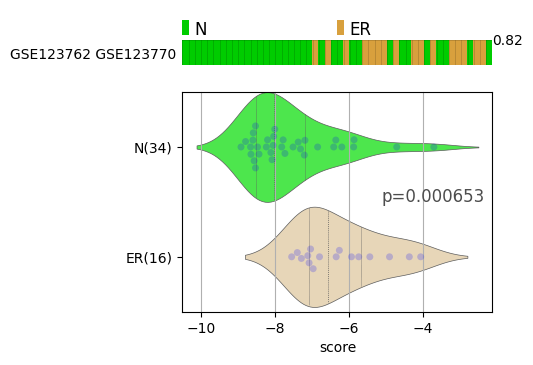

In [14]:
wt1, l1 = [1], [['FCER1A','MS4A2', 'CMA1', 'SLC18A2', 'TPSAB1', 'MRGPRX2']]
ana = bone.IBDAnalysis()
ana.prepareData("BC106")
atype = ana.h.getSurvName('c tissue type')
atypes = ['N', 'ER']
ahash = {'ER+ invasive breast cancer':1, 'Normal breast':0}
ana.initData(atype, atypes, ahash)
ana.orderData(l1, wt1)
fig = mut.plotViolinBar(ana, ana.h.getSource())
# plt.savefig("pdf-res/Figure5-13-GSE123762-GSE123770.pdf",dpi=400,bbox_inches="tight")
ana.printAllPvals()
# ax, bp = ana.printGene('TPSAB1', None, {'violin':1, 'vert':1, 'w':3, 'h':4})
# ax, bp = ana.printGene('MRGPRX2', None, {'violin':1, 'vert':1, 'w':3, 'h':4})


Liao 2022 bc (n = 40)
GSE173991 http://hegemon.ucsd.edu/Tools/explore.php?key=polyps&id=BC105
33 [9, 9, 15] GSE173991 http://hegemon.ucsd.edu/Tools/explore.php?key=polyps&id=BC105 BC105
[4]
N vs ER 0.329, 0.748
N vs TNBC 3.28, 0.00385
ER vs TNBC 2.15, 0.0445


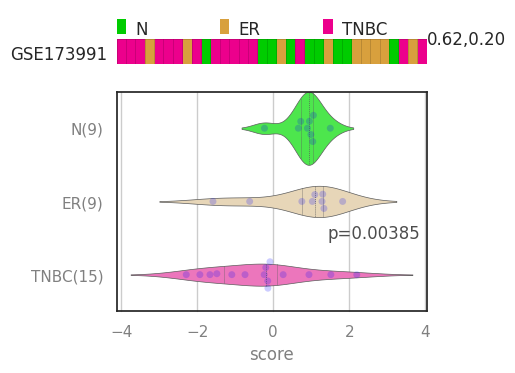

In [15]:
wt1, l1 = [1], [['FCER1A','MS4A2', 'CMA1', 'SLC18A2', 'TPSAB1', 'MRGPRX2']]
ana = bone.IBDAnalysis()
ana.prepareData("BC105")
atype = ana.h.getSurvName('c Type')
atypes = ['N', 'ER', 'TNBC']
ahash = {'TNBC':2, 'ER':1, 'Normal-':0}
ana.initData(atype, atypes, ahash)
ana.orderData(l1, wt1)
fig = mut.plotViolinBar(ana, ana.h.getSource())
# plt.savefig("pdf-res/Figure5-12-GSE173991.pdf",dpi=400,bbox_inches="tight")
ana.printAllPvals()


Dugo 2026 pre- and on-treatment NeoTRIP (n = 401)
GSE319641 http://hegemon.ucsd.edu/Tools/explore.php?key=polyps&id=BC98
300 [150, 150] GSE319641 http://hegemon.ucsd.edu/Tools/explore.php?key=polyps&id=BC98 BC98
[6]
Matched patients: 150; paired Wilcoxon p = 2.92e-17


/mnt/booleanfs2/sahoo/Data/BooleanLab/venv/lib/python3.6/site-packages/seaborn/categorical.py:1296: UserWarning: 14.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


Text(0.5, 1.02, 'p=2.92e-17')

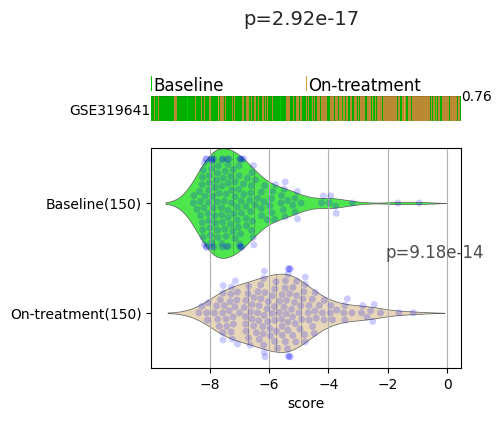

In [6]:
from scipy.stats import wilcoxon

wt1, l1 = [1], [['FCER1A', 'MS4A2', 'CMA1', 'SLC18A2', 'TPSAB1', 'MRGPRX2']]

ana = bone.IBDAnalysis()
ana.prepareData("BC98")

atype = list(ana.h.getSurvName('c Type'))
patient = ana.h.getSurvName('c patient id')
pre = {patient[i]: i for i in ana.h.aRange()
       if atype[i] == 'baseline' and patient[i]}
post = {patient[i]: i for i in ana.h.aRange()
        if atype[i] == 'day 1 of cycle 2' and patient[i]}

paired = sorted(set(pre) & set(post))
keep = {pre[p] for p in paired} | {post[p] for p in paired}

for i in ana.h.aRange():
    if i not in keep:
        atype[i] = None

atypes = ['Baseline', 'On-treatment']
ahash = {'baseline': 0, 'day 1 of cycle 2': 1}

ana.initData(atype, atypes, ahash)
ana.orderData(l1, wt1)
idx = list(ana.h.aRange())
assert len(ana.f_ranks) == len(idx), "Check score alignment"
scores = dict(zip(idx, ana.f_ranks))

change = [scores[post[p]] - scores[pre[p]] for p in paired]
pvalue = wilcoxon(change).pvalue

fig = mut.plotViolinBar(ana, ana.h.getSource())
print("Matched patients: %d; paired Wilcoxon p = %.3g"
      % (len(paired), pvalue))
strname = str('p='+'%.3g' %pvalue)
plt.gcf().suptitle(strname, fontsize=14, y=1.02)
# plt.gcf().savefig(f'pdf-res/Figure5-G-NEW-NeoTRIP-paired.pdf', dpi=100, transparent=True, bbox_inches='tight')


# fig.savefig("pdf-res/Figure5-G-NEW-NeoTRIP-paired.pdf", dpi=400, bbox_inches="tight")

Dadiani 2025 pre/post chemo adj normal (n = 84)
GSE217624 http://hegemon.ucsd.edu/Tools/explore.php?key=polyps&id=BC84
50 [25, 25] GSE217624 http://hegemon.ucsd.edu/Tools/explore.php?key=polyps&id=BC84 BC84
[6]
Matched patients: 25; paired Wilcoxon p = 0.000103


Text(0.5, 1.02, 'p=0.000103')

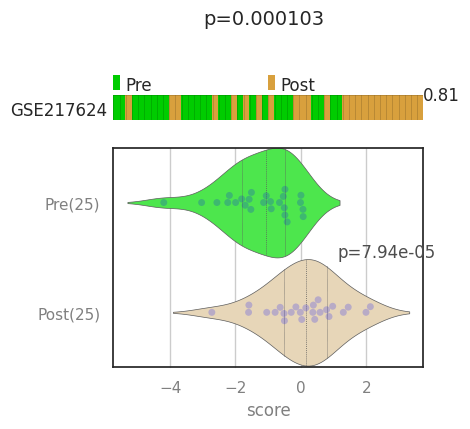

In [7]:
import re
from scipy.stats import wilcoxon

wt1, l1 = [1], [['FCER1A', 'MS4A2', 'CMA1', 'SLC18A2', 'TPSAB1', 'MRGPRX2']]

ana = bone.IBDAnalysis()
ana.prepareData("BC84")

atype = list(ana.h.getSurvName('c treatment'))
title = ana.h.getSurvName('c Title')
tissue = ana.h.getSurvName('c tissue')

# Tumor samples only; retain ST-52's left-side pair.
# ST_57R is excluded pending clarification of its timing.
exclude = {'ST_52C__Rt', 'ST_52T__Rt', 'ST_57R'}
patient = [None] * len(atype)

for i in ana.h.aRange():
    match = re.match(r'^ST_(\d+)[CT](?:_|$)', str(title[i]))
    if tissue[i] == 'breast cancer tumor' and title[i] not in exclude and match:
        patient[i] = match.group(1)

pre = {patient[i]: i for i in ana.h.aRange()
       if atype[i] == 'pre-treatment' and patient[i]}
post = {patient[i]: i for i in ana.h.aRange()
        if atype[i] == 'post-treatment' and patient[i]}

paired = sorted(set(pre) & set(post))
keep = {pre[p] for p in paired} | {post[p] for p in paired}

for i in ana.h.aRange():
    if i not in keep:
        atype[i] = None

atypes = ['Pre', 'Post']
ahash = {'pre-treatment': 0, 'post-treatment': 1}

ana.initData(atype, atypes, ahash)
ana.orderData(l1, wt1)
idx = list(ana.h.aRange())
assert len(ana.f_ranks) == len(idx), "Check score alignment"
scores = dict(zip(idx, ana.f_ranks))

change = [scores[post[p]] - scores[pre[p]] for p in paired]
pvalue = wilcoxon(change).pvalue

fig = mut.plotViolinBar(ana, ana.h.getSource())
print("Matched patients: %d; paired Wilcoxon p = %.3g"
      % (len(paired), pvalue))
strname = str('p='+'%.3g' %pvalue)
plt.gcf().suptitle(strname, fontsize=14, y=1.02)
# plt.gcf().savefig(f'pdf-res/Figure5-H-NEW-Dadiani-paired.pdf', dpi=100, transparent=True, bbox_inches='tight')

# fig.savefig("pdf-res/Figure5-Dadiani-paired.pdf",
#             dpi=400, bbox_inches="tight")

Derouane 2024 before and after neoadjuvant chemo (n = 122)
GSE240671 http://hegemon.ucsd.edu/Tools/explore.php?key=polyps&id=BC96
54 [27, 27] GSE240671 http://hegemon.ucsd.edu/Tools/explore.php?key=polyps&id=BC96 BC96
[6]
Matched patients: 27; paired Wilcoxon p = 0.000147


Text(0.5, 1.02, 'p=0.000147')

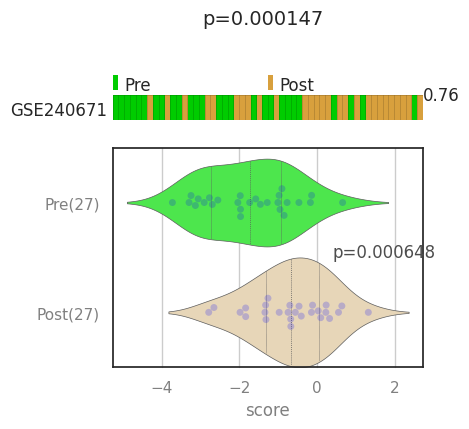

In [8]:
from scipy.stats import wilcoxon

wt1, l1 = [1], [['FCER1A', 'MS4A2', 'CMA1', 'SLC18A2', 'TPSAB1', 'MRGPRX2']]

ana = bone.IBDAnalysis()
ana.prepareData("BC96")

atype = list(ana.h.getSurvName('c timing biopsies'))
patient = ana.h.getSurvName('c patient id')
pre = {patient[i]: i for i in ana.h.aRange()
       if atype[i] == 'pre-surgery' and patient[i]}
post = {patient[i]: i for i in ana.h.aRange()
        if atype[i] == 'post-surgery' and patient[i]}

paired = sorted(set(pre) & set(post))
keep = {pre[p] for p in paired} | {post[p] for p in paired}

for i in ana.h.aRange():
    if i not in keep:
        atype[i] = None

atypes = ['Pre', 'Post']
ahash = {'pre-surgery': 0, 'post-surgery': 1}

ana.initData(atype, atypes, ahash)
ana.orderData(l1, wt1)
idx = list(ana.h.aRange())
assert len(ana.f_ranks) == len(idx), "Check score alignment"
scores = dict(zip(idx, ana.f_ranks))

change = [scores[post[p]] - scores[pre[p]] for p in paired]
pvalue = wilcoxon(change).pvalue

fig = mut.plotViolinBar(ana, ana.h.getSource())
print("Matched patients: %d; paired Wilcoxon p = %.3g"
      % (len(paired), pvalue))

strname = str('p='+'%.3g' %pvalue)
plt.gcf().suptitle(strname, fontsize=14, y=1.02)
# plt.gcf().savefig(f'pdf-res/Figure5-I-NEW-Derouane-paired.pdf', dpi=100, transparent=True, bbox_inches='tight')


# fig.savefig("pdf-res/Figure5-Derouane-paired.pdf",
#             dpi=400, bbox_inches="tight")

TCGA 2015 BRCA mRNA (n = 1215)
TCGA http://hegemon.ucsd.edu/Tools/explore.php?key=polyps&id=BC50.1
1094 [990, 104] TCGA http://hegemon.ucsd.edu/Tools/explore.php?key=polyps&id=BC50.1 BC50.1
[6]
[6]
[-0.672959148269346, 750.233532860108, -1.172959148269346, -0.172959148269346]
0.5765656793006839 -0.672959148269346


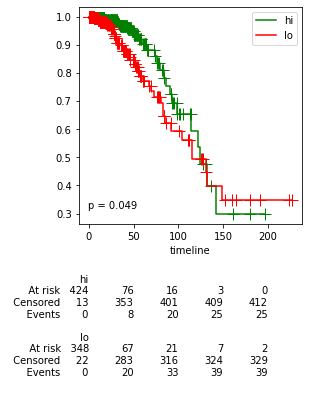

In [3]:
wt1, l1 = [1], [['FCER1A','MS4A2', 'CMA1', 'SLC18A2', 'TPSAB1', 'MRGPRX2']]
ana = bone.IBDAnalysis()
ana.getSurvival('BC50.1')
er = ana.h.getSurvName('c ER')
erpos = [i for i in ana.h.aRange() if er[i] == 'Positive']
erneg = [i for i in ana.h.aRange() if er[i] == 'Negative']
ana.orderData(l1, wt1)
thr = hu.getThrData(ana.f_ranks)
ranks, nm = bone.getNoiseMargin(ana.h, l1, wt1)
fthr = thr[0]
hi = [i for i in erpos if ana.f_ranks[i-2] > fthr]
lo = [i for i in erpos if ana.f_ranks[i-2] <= fthr]
group = [ ['hi', 'green', hi], ['lo', 'red', lo]]
ax,bp = ana.printSurvival(fthr = None, pG = group, genex = None, ct = None, ax = None)
# plt.savefig("pdf-res/Figure5-A-SIG_TCGA 2015 BRCA mRNA.pdf",dpi=400,bbox_inches="tight")

Metabric Breast Cancer OS (n = 2136)
METABRIC http://hegemon.ucsd.edu/Tools/explore.php?key=polyps&id=BC36
1972 [1081, 891] METABRIC http://hegemon.ucsd.edu/Tools/explore.php?key=polyps&id=BC36 BC36
[8]
[8]
[-4.8421062212242205, 1261.4460733974136, -5.3421062212242205, -4.3421062212242205]
0.7719471096120045 -4.8421062212242205


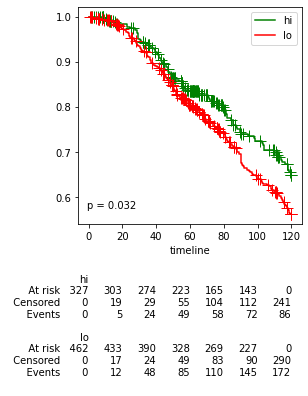

In [4]:
wt1, l1 = [1], [['FCER1A','MS4A2', 'CMA1', 'SLC18A2', 'TPSAB1', 'MRGPRX2']]
ana = bone.IBDAnalysis()
ana.getSurvival('BC36')
er = ana.h.getSurvName('c ER.Expr')
erpos = [i for i in ana.h.aRange() if er[i] == '+']
erneg = [i for i in ana.h.aRange() if er[i] == '-']
ana.orderData(l1, wt1)
thr = hu.getThrData(ana.f_ranks)
ranks, nm = bone.getNoiseMargin(ana.h, l1, wt1)
fthr = thr[0]
hi = [i for i in erpos if ana.f_ranks[i-2] > fthr]
lo = [i for i in erpos if ana.f_ranks[i-2] <= fthr]
group = [ ['hi', 'green', hi], ['lo', 'red', lo]]
ax,bp = ana.printSurvival(fthr = None, pG = group, genex = None, ct = 120, ax = None)
# plt.savefig("pdf-res/Figure5-B-SIG-METBric.pdf",dpi=400,bbox_inches="tight")

Bos 2009 Breast Cancer (n = 572)
GSE2034 GSE2603 GSE12276 http://hegemon.ucsd.edu/Tools/explore.php?key=polyps&id=BC20
572 [268, 304] GSE2034 GSE2603 GSE12276 http://hegemon.ucsd.edu/Tools/explore.php?key=polyps&id=BC20 BC20
[12]
[12]
[-4.522368051734192, 309.0567063694511, -5.022368051734192, -4.022368051734192]
1.5039695830085122 -4.522368051734192


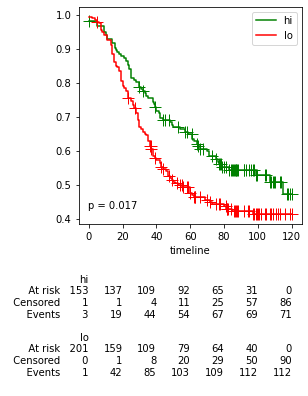

In [5]:
wt1, l1 = [1], [['FCER1A','MS4A2', 'CMA1', 'SLC18A2', 'TPSAB1', 'MRGPRX2']]
ana = bone.IBDAnalysis()
ana.getSurvival('BC20')
er = ana.h.getExprData('205225_at') #ESR1
erthr = ana.h.getThrData('205225_at')
erpos = [i for i in ana.h.aRange() if float(er[i]) > erthr[0]]
erneg = [i for i in ana.h.aRange() if float(er[i]) <= erthr[0]]
ana.orderData(l1, wt1)
thr = hu.getThrData(ana.f_ranks)
ranks, nm = bone.getNoiseMargin(ana.h, l1, wt1)
fthr = thr[0]
hi = [i for i in erpos if ana.f_ranks[i-2] > fthr]
lo = [i for i in erpos if ana.f_ranks[i-2] <= fthr]
group = [ ['hi', 'green', hi], ['lo', 'red', lo]]
ax,bp = ana.printSurvival(fthr = None, pG = group, genex = None, ct = 120, ax = None)
# plt.savefig("pdf-res/Figure5-C-BOSS-ESR1.pdf",dpi=400,bbox_inches="tight")

TCGA 2015 BRCA mRNA (n = 1215)
TCGA http://hegemon.ucsd.edu/Tools/explore.php?key=polyps&id=BC50.1
1094 [990, 104] TCGA http://hegemon.ucsd.edu/Tools/explore.php?key=polyps&id=BC50.1 BC50.1
[6]
TCGA-all n = 694 events = 48
TCGA-ERpos n = 534 events = 30


/mnt/booleanfs2/sahoo/Data/BooleanLab/venv/lib/python3.6/site-packages/ipykernel_launcher.py:40: MatplotlibDeprecationWarning: The 'basex' parameter of __init__() has been renamed 'base' since Matplotlib 3.3; support for the old name will be dropped two minor releases later.
/mnt/booleanfs2/sahoo/Data/BooleanLab/venv/lib/python3.6/site-packages/ipykernel_launcher.py:40: MatplotlibDeprecationWarning: The 'basex' parameter of __init__() has been renamed 'base' since Matplotlib 3.3; support for the old name will be dropped two minor releases later.


Metabric Breast Cancer OS (n = 2136)
METABRIC http://hegemon.ucsd.edu/Tools/explore.php?key=polyps&id=BC36
1972 [1081, 891] METABRIC http://hegemon.ucsd.edu/Tools/explore.php?key=polyps&id=BC36 BC36
[8]
METABRIC-all n = 1861 events = 677
METABRIC-ERpos n = 1419 events = 475


/mnt/booleanfs2/sahoo/Data/BooleanLab/venv/lib/python3.6/site-packages/ipykernel_launcher.py:40: MatplotlibDeprecationWarning: The 'basex' parameter of __init__() has been renamed 'base' since Matplotlib 3.3; support for the old name will be dropped two minor releases later.
/mnt/booleanfs2/sahoo/Data/BooleanLab/venv/lib/python3.6/site-packages/ipykernel_launcher.py:40: MatplotlibDeprecationWarning: The 'basex' parameter of __init__() has been renamed 'base' since Matplotlib 3.3; support for the old name will be dropped two minor releases later.


Bos 2009 Breast Cancer (n = 572)
GSE2034 GSE2603 GSE12276 http://hegemon.ucsd.edu/Tools/explore.php?key=polyps&id=BC20
572 [268, 304] GSE2034 GSE2603 GSE12276 http://hegemon.ucsd.edu/Tools/explore.php?key=polyps&id=BC20 BC20
[12]
Bos-all n = 425 events = 258


/mnt/booleanfs2/sahoo/Data/BooleanLab/venv/lib/python3.6/site-packages/ipykernel_launcher.py:40: MatplotlibDeprecationWarning: The 'basex' parameter of __init__() has been renamed 'base' since Matplotlib 3.3; support for the old name will be dropped two minor releases later.
/mnt/booleanfs2/sahoo/Data/BooleanLab/venv/lib/python3.6/site-packages/ipykernel_launcher.py:40: MatplotlibDeprecationWarning: The 'basex' parameter of __init__() has been renamed 'base' since Matplotlib 3.3; support for the old name will be dropped two minor releases later.


Bos-ERpos n = 249 events = 146


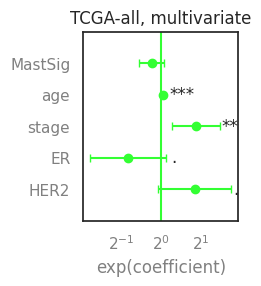

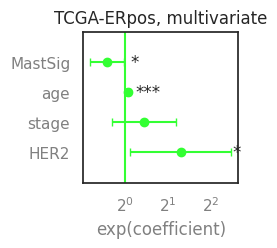

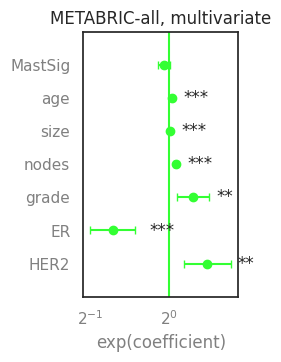

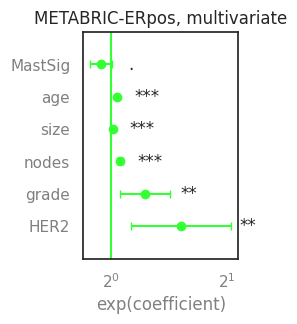

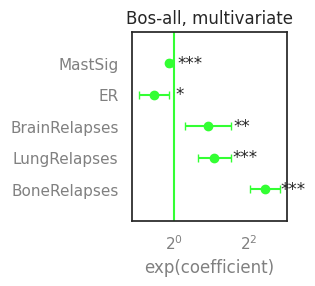

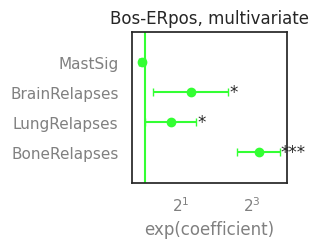

In [14]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import bone
hu = bone.hu

SIG = [['FCER1A', 'MS4A2', 'CMA1', 'SLC18A2', 'TPSAB1', 'MRGPRX2']]
# EPI = [['EPCAM', 'KRT8', 'KRT18', 'KRT19', 'CDH1']] 
HORIZON = 120   


def num(k):
    try:
        return float(k)
    except (TypeError, ValueError):
        return None
def col(ana, name, ahash=None):
    v = ana.h.getSurvName(name)
    return [num(k) for k in v] if ahash is None else [ahash.get(k) for k in v]
def stage(k):
    m = re.search(r'Stage (IV|III|II|I)', str(k))
    return {'I': 1, 'II': 2, 'III': 3, 'IV': 4}[m.group(1)] if m else None
def score(ana):
    ana.orderData(SIG, [1])
#     ana.orderData(EPI, [1])
    return [None] * ana.h.start + list(ana.f_ranks)


def run(df, cols, name):
    d = df[['time', 'status', 'MastSig'] + cols].dropna().astype(float)
    over = d['time'] > HORIZON
    d.loc[over, 'status'] = 0
    d.loc[over, 'time'] = HORIZON
    print(name, 'n =', len(d), 'events =', int(d['status'].sum()))
    dfu, dfm = hu.Multivariate(d.astype(str))   
#     for kind, res in [('univariate', dfu), ('multivariate', dfm)]:
    for kind, res in [('multivariate', dfm)]:
        ax = hu.plotCoef(res)
        ax.set_xscale('log', basex=2)
        ax.set_title('%s, %s' % (name, kind))
#         ax.figure.savefig('pdf-res/Fig5-supp-%s-%s.pdf' % (name, kind), dpi=400, bbox_inches='tight')
    return dfu, dfm


# ---- TCGA 
ana = bone.IBDAnalysis()
ana.getSurvival('BC50.1')
df = pd.DataFrame()
df['time'] = col(ana, 'time')
df['status'] = col(ana, 'status')
df['age'] = col(ana, 'c Age')
df['stage'] = [stage(k) for k in ana.h.getSurvName('c Stage')]
df['ER'] = col(ana, 'c ER', {'Positive': 1, 'Negative': 0})
df['HER2'] = col(ana, 'c Her2', {'Positive': 1, 'Negative': 0})
df['female'] = col(ana, 'c Sex', {'FEMALE': 1})
df['untreated'] = col(ana, 'c pretreatment_history', {'No': 1})
df['MastSig'] = score(ana)
df = df[(df['female'] == 1) & (df['untreated'] == 1)]
tcga = [run(df, ['age', 'stage', 'ER', 'HER2'], 'TCGA-all'),
        run(df[df['ER'] == 1], ['age', 'stage', 'HER2'], 'TCGA-ERpos')]

# ---- METABRIC 
ana = bone.IBDAnalysis()
ana.getSurvival('BC36')
df = pd.DataFrame()
days = col(ana, 'c T')                      
df['time'] = [t if t is not None else (d / 30 if d is not None else None)
              for t, d in zip(col(ana, 'time'), days)]
df['status'] = col(ana, 'status')
df['age'] = col(ana, 'c age_at_diagnosis')
df['size'] = col(ana, 'c size')
df['nodes'] = col(ana, 'c lymph_nodes_positive')
df['grade'] = col(ana, 'c grade')
df['ER'] = col(ana, 'c ER.Expr', {'+': 1, '-': 0})
df['HER2'] = col(ana, 'c Her2.Expr', {'+': 1, '-': 0})
df['tumor'] = col(ana, 'c Type', {'discovery': 1, 'validation': 1})   
df['MastSig'] = score(ana)
df = df[df['tumor'] == 1]
metabric = [run(df, ['age', 'size', 'nodes', 'grade', 'ER', 'HER2'], 'METABRIC-all'),
            run(df[df['ER'] == 1], ['age', 'size', 'nodes', 'grade', 'HER2'], 'METABRIC-ERpos')]

# ---- Boss 
ana = bone.IBDAnalysis()
ana.getSurvival('BC20')
df = pd.DataFrame()
df['time'] = col(ana, 'time')
df['status'] = col(ana, 'status')
esr1 = ana.h.getExprData('205225_at')
thr = ana.h.getThrData('205225_at')[0]
df['ER'] = [None if num(k) is None else int(num(k) > thr) for k in esr1]  
df['BrainRelapses'] = col(ana, 'c Brain relapses')
df['LungRelapses'] = col(ana, 'c Lung relapses')
df['BoneRelapses'] = col(ana, 'c Bone relapses')
df['MastSig'] = score(ana)
bos = [run(df, ['ER' ,'BrainRelapses', 'LungRelapses', 'BoneRelapses'], 'Bos-all'),
       run(df[df['ER'] == 1], ['BrainRelapses', 'LungRelapses', 'BoneRelapses'], 'Bos-ERpos')]


In [11]:
rows = []
for cohort, results in [('TCGA', tcga), ('METABRIC', metabric), ('GSE2034 GSE2603 GSE12276', bos)]:
    for model, (dfu, dfm) in zip(['All patients', 'ER-positive'], results):
        for kind, res in [('univariate', dfu), ('multivariate', dfm)]:
            t = res[['exp(coef)', 'lower .95', 'upper .95', 'p']].copy()
            t.columns = ['HR', 'lower95', 'upper95', 'p']
            t.insert(0, 'analysis', kind)
            t.insert(0, 'model', model)
            t.insert(0, 'cohort', cohort)
            rows.append(t)

table = pd.concat(rows).rename_axis('variable').reset_index()
table.to_csv('pdf-res/TableS-multivariate.csv', index=False)
table.round(3)

,variable,cohort,model,analysis,HR,lower95,upper95,p
0,MastSig,TCGA,All patients,univariate,0.800,0.664,0.963,0.019
1,age,TCGA,All patients,univariate,1.033,1.012,1.054,0.002
2,stage,TCGA,All patients,univariate,1.865,1.259,2.762,0.002
3,ER,TCGA,All patients,univariate,0.488,0.272,0.877,0.017
4,HER2,TCGA,All patients,univariate,2.260,1.234,4.137,0.008
...,...,...,...,...,...,...,...,...
57,BoneRelapses,GSE2034 GSE2603 GSE12276,ER-positive,univariate,9.207,6.160,13.762,0.000
58,MastSig,GSE2034 GSE2603 GSE12276,ER-positive,multivariate,0.951,0.893,1.013,0.122
59,BrainRelapses,GSE2034 GSE2603 GSE12276,ER-positive,multivariate,2.447,1.184,5.057,0.016
60,LungRelapses,GSE2034 GSE2603 GSE12276,ER-positive,multivariate,1.652,1.011,2.699,0.045
